# Supplementary Figure S2e. Type I error of TransMap-local and alternative tests under the null

Type I error under null simulations with 0% causal trans-genes (m = 0, s = 0) at nominal α = 10⁻⁵, shown as the ratio of estimated T1E to α, across sample sizes (colours), module sizes M = 20/50/100 (rows) and residual correlations ρ = 0.1/0.3/0.5 (columns). T1E is the mean within-dataset fraction of tested variants with p < α over 10⁸ simulated datasets per setting (1,000 batches × 100,000 datasets; one setting, n = 800, M = 100, ρ = 0.3, has 969 completed batches). Error bars are 95% confidence intervals from the normal approximation across datasets (estimate ± 1.96 × Monte Carlo SE), divided by α. The dashed line marks T1E = α. The rds also keeps estimates at α = 0.05, 0.01, 10⁻³ and 10⁻⁴.

Input: `data/Figure_S2e_type1_error.rds`.

In [1]:
library(ggplot2)
t1e <- readRDS("data/Figure_S2e_type1_error.rds")
head(t1e)
table(t1e$alpha)

,n,M,rho,method,alpha,t1e,mc_se,ci_lower,ci_upper,interval_method,n_batches,n_datasets,n_variant_tests
,<int>,<int>,<dbl>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<int>,<int>,<int>
1,400,20,0.1,trans-eGene,5e-02,4.876002e-02,2.069760e-05,4.871945e-02,4.880059e-02,normal_dataset_clt,1000,100000000,117660743
2,400,20,0.1,trans-eGene,1e-02,9.928597e-03,9.528993e-06,9.909920e-03,9.947273e-03,normal_dataset_clt,1000,100000000,117660743
3,400,20,0.1,trans-eGene,1e-03,9.967767e-04,3.033228e-06,9.908316e-04,1.002722e-03,normal_dataset_clt,1000,100000000,117660743
4,400,20,0.1,trans-eGene,1e-04,1.005683e-04,9.644264e-07,9.867809e-05,1.024586e-04,normal_dataset_clt,1000,100000000,117660743
5,400,20,0.1,trans-eGene,1e-05,9.313333e-06,2.921648e-07,8.740701e-06,9.885966e-06,normal_dataset_clt,1000,100000000,117660743
6,400,20,0.1,Eigengene,5e-02,5.000331e-02,2.094594e-05,4.996226e-02,5.004436e-02,normal_dataset_clt,1000,100000000,117660743



1e-05 1e-04 0.001  0.01  0.05 
  144   144   144   144   144 

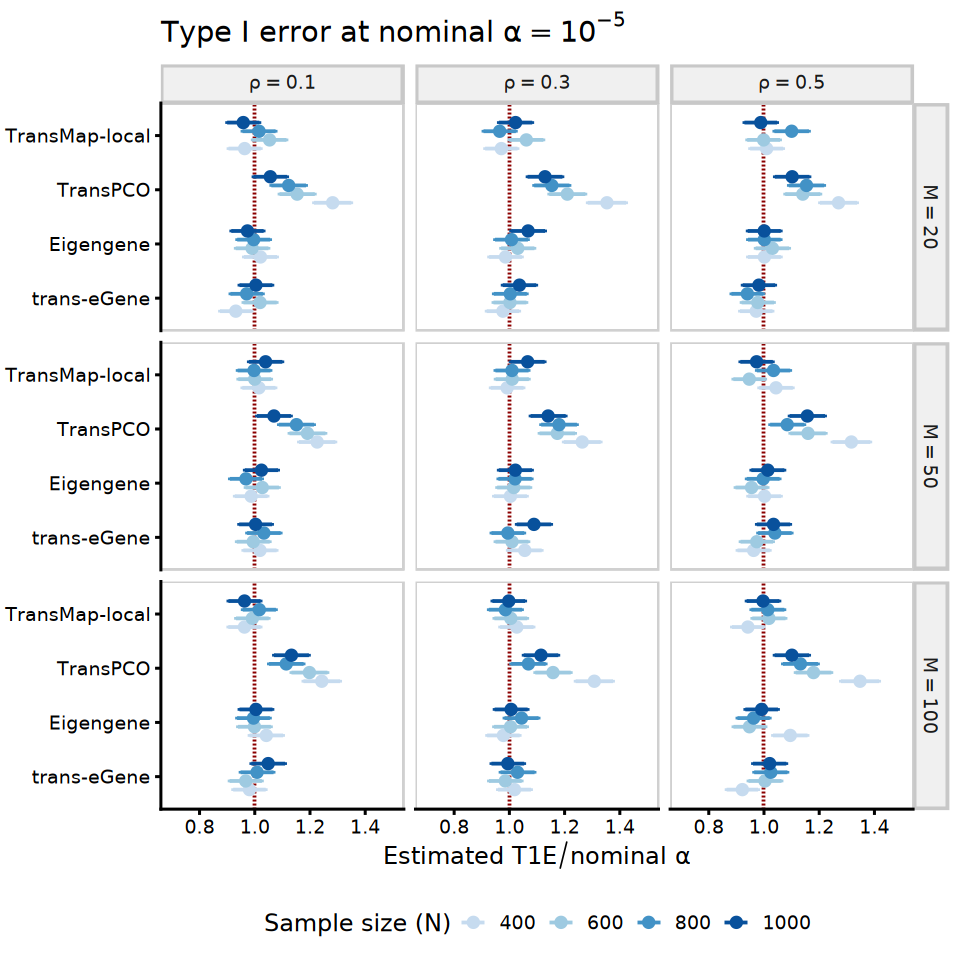

In [2]:
target_alpha <- 1e-5
d <- t1e[abs(t1e$alpha - target_alpha) < 1e-12, ]
d$ratio <- d$t1e / target_alpha
d$ratio_low <- d$ci_lower / target_alpha
d$ratio_high <- d$ci_upper / target_alpha
d$method <- factor(d$method, levels = rev(c("TransMap-local", "TransPCO", "Eigengene", "trans-eGene")))
d$sample_size <- factor(d$n, levels = c(400, 600, 800, 1000))
d$M_label <- factor(paste0("M == ", d$M), levels = paste0("M == ", c(20, 50, 100)))
d$rho_label <- factor(paste0("rho == ", format(d$rho, nsmall = 1)), levels = paste0("rho == ", c("0.1", "0.3", "0.5")))
size_colors <- c("400" = "#C6DBEF", "600" = "#9ECAE1", "800" = "#4292C6", "1000" = "#08519C")
dodge <- position_dodge(width = 0.64)

p <- ggplot(d, aes(x = method, y = ratio, colour = sample_size, group = sample_size)) +
  geom_hline(yintercept = 1, linetype = "22", colour = "darkred", linewidth = 0.8) +
  geom_errorbar(aes(ymin = ratio_low, ymax = ratio_high), position = dodge, width = 0.2, linewidth = 0.8) +
  geom_point(position = dodge, size = 2.5) +
  coord_flip(ylim = c(0.7, 1.5)) +
  facet_grid(M_label ~ rho_label, labeller = label_parsed) +
  scale_colour_manual(values = size_colors, name = "Sample size (N)") +
  labs(title = expression(Type~I~error~at~nominal~alpha == 10^-5), x = NULL,
       y = expression(Estimated~T1E/nominal~alpha)) +
  theme_classic(base_size = 14) +
  theme(strip.background = element_rect(fill = "#F0F0F0", colour = "#C8C8C8"),
        panel.border = element_rect(fill = NA, colour = "#D0D0D0"),
        legend.position = "bottom")

options(repr.plot.width = 8, repr.plot.height = 8)
p